# 01. Klasifikasi URL — KNN + TF-IDF Karakter (Versi Pribadi / VP)

Notebook ini dibangun **dari nol** sebagai eksperimen pribadi: preprocessing dan KNN-nya
dirancang sendiri, **tidak** mengikuti protokol notebook kelompok. Datasetnya sama:
`Malicious URL Detection (1).csv` (783.705 URL, 7 kelas: benign, defacement, exploit,
legitimate, malware, phishing, spam).

**Keputusan desain versi ini** (alasannya dijelaskan di tiap bagian):

1. **Pembersihan:** buang baris kosong, URL dengan label bertentangan, dan duplikat exact.
2. **Seluruh 783.702 baris bersih dipakai** (tanpa sampling) — konsekuensinya KNN
   harus menghitung jarak ke ±548 ribu baris train untuk setiap prediksi; sweep dan
   evaluasi bisa memakan waktu berjam-jam (lihat peringatan di Bagian 3).
3. **Split 70/15/15** (train/validation/test), stratified dan acak.
4. **Fitur: TF-IDF char_wb 3–5 gram** — kosakata dipelajari **hanya dari train**.
5. **Model: KNN** dengan jarak cosine + bobot distance; nilai `k` dipilih lewat
   sweep kecil di **validation**, lalu test dipakai **sekali** di akhir.
6. **Metrik utama: macro F1** — dataset sangat timpang, accuracy bisa menipu.

Alur: setup → muat & bersihkan → EDA kelas → split seluruh data → TF-IDF → sweep k →
evaluasi test → simpan hasil.

## 0. Preprocessing itu apa? (ringkasan konsep)

Data mentah tidak bisa langsung "dimakan" model. Preprocessing membuatnya:

1. **Bersih** — tidak ada baris kosong, label rusak, atau duplikat yang bisa membocorkan jawaban.
2. **Seragam** — teks URL diubah jadi angka (vektor), dan skalanya dibuat adil supaya
   tidak ada satu ciri pun yang mendominasi perhitungan jarak.
3. **Aman** — semua yang "dipelajari" dari data (kosakata TF-IDF) hanya berasal dari
   bagian train; validation/test tidak boleh mengajari model apa pun.

KNN khusus menuntut poin 2 secara ketat: karena keputusannya 100% berbasis
"siapa tetangga terdekatku", fitur berskala besar akan menenggelamkan fitur lain
bila tidak dinormalisasi.

In [2]:
from pathlib import Path
import json
import sys
import time
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---------- konstanta eksperimen (silakan ubah di sini) ----------
SEED = 42
SPLIT_TEST = 0.30             # 30% dibagi lagi jadi validation & test -> 70/15/15
MAX_FEATURES = 50_000         # batas kosakata TF-IDF; turunkan (mis. 30_000) bila ingin lebih cepat
K_CANDIDATES = [3, 5, 7, 9]   # kandidat k untuk sweep; tiap k = 1 prediksi validation penuh (lambat!)

DATA_CANDIDATES = [
    Path("../dataset/Malicious URL Detection (1).csv"),
    Path("Malicious URL Detection (1).csv"),
]
DATA_FILE = next((p for p in DATA_CANDIDATES if p.exists()), DATA_CANDIDATES[0])
RESULTS_DIR = Path("results_vp")
RESULTS_DIR.mkdir(exist_ok=True)

print("Python  :", sys.executable)
print("Dataset :", DATA_FILE.resolve())
versi = {n: importlib.metadata.version(n)
         for n in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib"]}
display(pd.Series(versi, name="versi").to_frame())

Python  : d:\Semester5\ML\244107020017_Machine_Learning\PBL\Exsperimen\.venv\Scripts\python.exe
Dataset : D:\Semester5\ML\244107020017_Machine_Learning\PBL\dataset\Malicious URL Detection (1).csv


,versi
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2


## 1. Muat dan bersihkan data

**Tujuan:** memastikan data layak pakai sebelum diapa-apakan.

- CSV dibaca sebagai **teks mentah** (semua kolom string) supaya tidak ada nilai yang
  diam-diam diubah pandas menjadi NaN/angka.
- Spasi di ujung URL dibuang; label diseragamkan jadi huruf kecil.
- **Baris kosong** (URL atau label kosong) dibuang.
- **URL dengan label bertentangan** (URL sama tapi kelasnya beda) dibuang — datanya
  ambigu, model tidak bisa belajar dari kontradiksi.
- **Duplikat exact dibuang.** Ini pilihan versi VP: karena split kita acak, duplikat
  yang tersisa bisa mendarat di train *dan* test sekaligus — model tinggal "menyalin
  jawaban" (kebocoran halus). Semua angka perubahan dicatat, tidak ada yang diam-diam.

In [2]:
if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset tidak ditemukan: {DATA_FILE.resolve()}")

raw = pd.read_csv(DATA_FILE, dtype=str, keep_default_na=False)
if not {"url", "type"} <= set(raw.columns):
    raise ValueError(f"Kolom dataset tidak sesuai: {raw.columns.tolist()}")
print(f"Baris mentah: {len(raw):,} | kolom: {raw.columns.tolist()}")

df = pd.DataFrame({
    "url": raw["url"].str.strip(),
    "label": raw["type"].str.strip().str.lower(),
})

# 1) buang baris dengan url/label kosong
n_kosong = int(((df.url == "") | (df.label == "")).sum())
df = df[(df.url != "") & (df.label != "")]

# 2) buang URL yang labellnya bertentangan (konservatif: seluruh URL-nya dibuang)
nunique = df.groupby("url")["label"].nunique()
url_konflik = set(nunique[nunique > 1].index)
df = df[~df.url.isin(url_konflik)]

# 3) buang duplikat exact, simpan kemunculan pertama
n_dup = int(df.duplicated(subset="url").sum())
df = df.drop_duplicates(subset="url", keep="first").reset_index(drop=True)

print(f"Baris kosong dibuang            : {n_kosong}")
print(f"URL berlabel konflik dibuang    : {len(url_konflik)}")
print(f"Duplikat exact dibuang          : {n_dup}")
print(f"Baris bersih                    : {len(df):,}")
print(f"Kelas                           : {sorted(df.label.unique())}")
df.head()

Baris mentah: 783,705 | kolom: ['url', 'type']
Baris kosong dibuang            : 0
URL berlabel konflik dibuang    : 0
Duplikat exact dibuang          : 3
Baris bersih                    : 783,702
Kelas                           : ['benign', 'defacement', 'exploit', 'legitimate', 'malware', 'phishing', 'spam']


,url,label
0,mp3raid.com/music/krizz_kaliko.html,benign
1,bopsecrets.org/rexroth/cr/1.htm,benign
2,buzzfil.net/m/show-art/ils-etaient-loin-de-s-i...,benign
3,espn.go.com/nba/player/_/id/3457/brandon-rush,benign
4,yourbittorrent.com/?q=anthony-hamilton-soulife,benign


## 2. EDA ringan: distribusi kelas

Sebelum lanjut, lihat dulu "medan perangnya". Dataset ini **sangat timpang**:
`benign` separuh lebih, sedangkan `exploit` cuma ratusan baris dari 783 ribu.

Konsekuensinya:

- Model pemalas bisa dapat accuracy ~54% hanya dengan menebak `benign` terus.
  Karena itu **accuracy bukan metrik utama** di sini — kita utamakan **macro F1**
  (rata-rata F1 semua kelas dengan bobot sama, sehingga kegagalan di kelas langka
  langsung terlihat).
- Split nanti harus **stratified** supaya komposisi kelas di train/validation/test
  tetap sama dengan aslinya.
- Grafik pakai skala log — kalau tidak, batang kelas kecil tidak akan kelihatan.

,jumlah,persen
label,,
benign,426432,54.4125
defacement,95263,12.1555
exploit,243,0.0310
legitimate,5809,0.7412
malware,23592,3.0103
phishing,229610,29.2981
spam,2753,0.3513


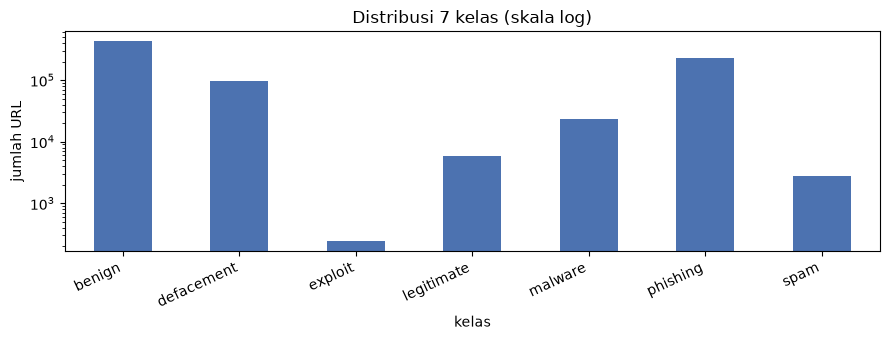

Kelas terbesar  : benign (54.41%)
Kelas terkecil  : exploit (0.0310%)


In [3]:
counts = df.label.value_counts().sort_index()
dist = pd.DataFrame({"jumlah": counts,
                     "persen": (counts / len(df) * 100).round(4)})
display(dist)

fig, ax = plt.subplots(figsize=(9, 3.5))
counts.plot.bar(ax=ax, color="#4c72b0")
ax.set(title="Distribusi 7 kelas (skala log)", xlabel="kelas", ylabel="jumlah URL")
ax.set_yscale("log")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print(f"Kelas terbesar  : {counts.idxmax()} ({counts.max() / len(df):.2%})")
print(f"Kelas terkecil  : {counts.idxmin()} ({counts.min() / len(df):.4%})")

## 3. Split 70/15/15 atas SELURUH data (tanpa sampling)

Versi VP memakai **seluruh 783.702 baris bersih** — tidak ada baris yang dibuang
setelah pembersihan. Semua baris dibagi stratified menjadi tiga partisi (komposisi
7 kelas dijaga sama seperti aslinya).

**Peran tiga partisi:**

- **train (±548 ribu baris)** — satu-satunya data yang boleh mengajari model (kosakata TF-IDF + tetangga KNN).
- **validation (±117 ribu baris)** — untuk memilih hyperparameter (nilai `k`) tanpa menyentuh test.
- **test (±117 ribu baris)** — "ujian nasional", dipakai **sekali** di akhir supaya skor tidak bocor
  ke proses pemilihan model.

⚠️ **Peringatan waktu jalan (baca sebelum menjalankan!):** KNN menyimpan seluruh train
dan menghitung jarak untuk *setiap* baris yang diprediksi. Dengan ±548 ribu baris train,
satu kali prediksi penuh (validation atau test) bisa memakan **puluhan menit** di laptop
biasa; sweep 4 nilai k = 4× prediksi validation. Total notebook ini bisa **3–5 jam**.
Kalau terlalu lama, kurangi `K_CANDIDATES` (misal jadi `[5]` saja) dan/atau turunkan
`MAX_FEATURES` — semuanya di sel konstanta paling atas.

**Catatan kejujuran (limitasi vs protokol kelompok):** split di sini acak per-baris,
jadi domain yang sama *bisa* muncul di dua partisi (misal dua subdomain situs yang
sama). Protokol kelompok memakai split domain-disjoint untuk mencegah ini. Skor VP
karena itu bisa sedikit lebih optimis; itu konsekuensi desain yang kita sadari.

In [4]:
from sklearn.model_selection import train_test_split

# split bertahap SELURUH data bersih: 70% train, sisanya dibagi dua -> 15% val, 15% test
train_df, tmp_df = train_test_split(df, test_size=SPLIT_TEST,
                                    stratify=df.label, random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.5,
                                   stratify=tmp_df.label, random_state=SEED)

tabel = pd.DataFrame({
    "train": train_df.label.value_counts(),
    "validation": val_df.label.value_counts(),
    "test": test_df.label.value_counts(),
}).sort_index()
display(tabel)
print(f"train {len(train_df):,} | validation {len(val_df):,} | test {len(test_df):,}")

# sanity check: tidak ada URL yang sama menyeberang partisi (duplikat sudah dibuang)
assert len(set(train_df.url) & set(val_df.url)) == 0
assert len(set(train_df.url) & set(test_df.url)) == 0
assert len(set(val_df.url) & set(test_df.url)) == 0
print("OK: tidak ada URL identik yang menyeberang partisi.")

X_train, y_train = train_df.url, train_df.label
X_val,   y_val   = val_df.url,   val_df.label
X_test,  y_test  = test_df.url,  test_df.label

,train,validation,test
label,,,
benign,298502,63965,63965
defacement,66684,14289,14290
exploit,170,37,36
legitimate,4066,872,871
malware,16515,3538,3539
phishing,160727,34441,34442
spam,1927,413,413


train 548,591 | validation 117,555 | test 117,556
OK: tidak ada URL identik yang menyeberang partisi.


### 3b. Cek host leak antar partisi

Split VP **acak per-baris**, bukan domain-disjoint. Duplikat exact sudah dibuang, tapi URL yang *berbeda* dengan **host/domain yang sama** tetap bisa mendarat di partisi berbeda. Sel ini mengukur seberapa parah host leak pada split yang barusan dibuat.

In [ ]:
import re

def ambil_host(u):
    u = u.strip()
    m = re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://([^/?#]+)", u)  # URL dengan scheme
    if m:
        return m.group(1).lower().rstrip(".")
    return u.split("/")[0].split("?")[0].lower().rstrip(".")  # tanpa scheme

host_train = set(X_train.map(ambil_host))
host_val   = set(X_val.map(ambil_host))
host_test  = set(X_test.map(ambil_host))

print(f"Host unik: train={len(host_train):,} | val={len(host_val):,} | test={len(host_test):,}")
print(f"train & val  : {len(host_train & host_val):,} host sama")
print(f"train & test : {len(host_train & host_test):,} host sama")
print(f"val   & test : {len(host_val & host_test):,} host sama")

leak_test = X_test.map(ambil_host).isin(host_train)
print(f"Baris test yang hostnya juga ada di train: {leak_test.sum():,} ({leak_test.mean():.1%} dari {len(X_test):,} baris test)")
print("Top-10 host test yang juga muncul di train:")
print(X_test[leak_test].map(ambil_host).value_counts().head(10).to_string())

## 4. Transformasi fitur: TF-IDF karakter

**Ide dasarnya:** setiap URL diubah jadi vektor angka berisi "pola fragmen karakter
apa saja yang ada, dan seberapa khas pola itu".

- **TF (term frequency)** — seberapa sering fragmen muncul di URL ini.
- **IDF (inverse document frequency)** — seberapa langka fragmen itu di seluruh
  dataset latih. Pola yang ada di mana-mana (`://`, `.com`) bobotnya kecil;
  pola khas (fragmen `login`, `verify`, `xn-`) bobotnya besar.
- **Nilai akhir = TF × IDF** → sidik jari komposisi pola per URL.

**Kenapa potongan karakter 3–5, bukan kata?** URL tidak punya spasi; bagian yang
menandakan kejahatan justru fragmen di tengah string. N-gram karakter menangkapnya
tanpa perlu tahu batas kata.

**Parameter versi VP dan alasannya:**

| Parameter | Nilai | Alasan |
|---|---|---|
| `analyzer` | `char_wb` | n-gram karakter dalam batas "kata" — mengurangi fragmen nyambung antar komponen |
| `ngram_range` | (3, 5) | fragmen pendek + konteks sedang |
| `lowercase` | `True` | versi ini memilih case-insensitive agar kosakata lebih hemat (berbeda dari protokol kelompok yang mempertahankan kapitalisasi) |
| `min_df` | 3 | pola yang muncul < 3 kali di train kemungkinan besar cuma noise |
| `max_features` | 50.000 | batas kosakata agar memori/waktu KNN terkendali |
| `sublinear_tf` | `True` | `1 + ln(tf)` — pengulangan tidak meledakkan bobot |
| `norm` | `l2` | panjang tiap vektor = 1 → jarak cosine membandingkan komposisi, bukan panjang URL |

**Prinsip anti-bocor:** `fit` (belajar kosakata + IDF) **hanya pada train**;
validation/test cuma di-`transform` memakai kosakata yang sudah dipelajari itu.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    lowercase=True,
    min_df=3,
    max_features=MAX_FEATURES,
    sublinear_tf=True,
    norm="l2",
    dtype=np.float32,
)

t0 = time.perf_counter()
Xtr = tfidf.fit_transform(X_train)   # FIT hanya pada train
Xva = tfidf.transform(X_val)         # transform saja
Xte = tfidf.transform(X_test)        # transform saja
print(f"Transformasi selesai dalam {time.perf_counter() - t0:.1f} detik")

print("Bentuk train      :", Xtr.shape)
print("Bentuk validation :", Xva.shape)
print("Bentuk test       :", Xte.shape)
print(f"Kosakata dipelajari: {len(tfidf.vocabulary_):,} pola")
kepadatan = Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1])
print(f"Matriks sparse     : hanya {kepadatan:.4%} sel terisi (sisanya nol, tidak disimpan)")

# intip fragmen yang ditangkap dari satu URL contoh
contoh = X_train.iloc[0]
fragmen = tfidf.build_analyzer()(contoh)
print("\nURL contoh      :", contoh[:90])
print("Sebagian fragmen:", fragmen[:15])

Transformasi selesai dalam 239.0 detik
Bentuk train      : (548591, 50000)
Bentuk validation : (117555, 50000)
Bentuk test       : (117556, 50000)
Kosakata dipelajari: 50,000 pola
Matriks sparse     : hanya 0.2100% sel terisi (sisanya nol, tidak disimpan)

URL contoh      : deducibly.ecotecbiotics.info/viewtopic.php?x=148&amp;u=3801&amp;yz=157
Sebagian fragmen: [' de', 'ded', 'edu', 'duc', 'uci', 'cib', 'ibl', 'bly', 'ly.', 'y.e', '.ec', 'eco', 'cot', 'ote', 'tec']


## 5. Model: KNN + sweep nilai k di validation

**Cara kerja KNN:** tidak ada "belajar rumus". Fase fit hanya *menyimpan* data train.
Saat prediksi: hitung jarak URL baru ke semua URL train, ambil `k` tetangga terdekat,
lalu voting label — dengan `weights="distance"` tetangga yang lebih dekat suaranya
lebih berat.

- `metric="cosine"` → bandingkan **komposisi pola** (arah vektor), bukan panjang URL.
  Karena vektor TF-IDF kita sudah L2-normalized, ini pilihan yang konsisten.
- `algorithm="brute"` → untuk matriks sparse, hitung jarak eksak ke semua baris
  (pohon/struktur indeks seperti kd-tree tidak berlaku di dimensi tinggi + sparse).
- `n_jobs=-1` → paralelkan prediksi ke semua core CPU.

⚠️ Dengan data penuh, **setiap iterasi sweep = satu prediksi penuh pada ±117 ribu
baris validation** — jangan kaget kalau tiap nilai k memakan puluhan menit
(lihat peringatan di Bagian 3).

**Kenapa k di-sweep di validation, bukan test?** Kalau kita memilih k dengan melihat
skor test, test berubah jadi "alat tuning" dan skornya tidak lagi jujur. Validation
ada persis untuk ini. `k` terlalu kecil → model sensitif ke satu tetangga (bisa noise);
`k` terlalu besar → keputusan didominasi mayoritas. Biarkan data yang memilih.

k=3: macro F1 validation = 0.8067  (1246.3 detik)
k=5: macro F1 validation = 0.8114  (831.3 detik)
k=7: macro F1 validation = 0.8105  (814.5 detik)
k=9: macro F1 validation = 0.8027  (776.3 detik)


,k,macro_f1_val,detik
0,3,0.8067,1246.3
1,5,0.8114,831.3
2,7,0.8105,814.5
3,9,0.8027,776.3


k terpilih (berdasarkan validation): 5


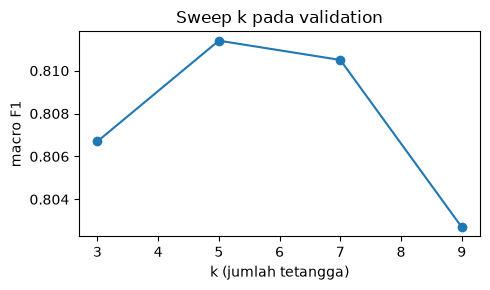

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score

def buat_knn(k):
    return KNeighborsClassifier(n_neighbors=k, weights="distance",
                                metric="cosine", algorithm="brute", n_jobs=-1)

hasil_sweep = []
for k in K_CANDIDATES:
    knn = buat_knn(k)
    t0 = time.perf_counter()
    knn.fit(Xtr, y_train)              # fit KNN = menyimpan data (murah)
    pred_val = knn.predict(Xva)        # bagian mahal: jarak ke semua baris train
    dt = time.perf_counter() - t0
    mf1 = f1_score(y_val, pred_val, average="macro", zero_division=0)
    hasil_sweep.append({"k": k, "macro_f1_val": round(float(mf1), 4),
                        "detik": round(dt, 1)})
    print(f"k={k}: macro F1 validation = {mf1:.4f}  ({dt:.1f} detik)")

sweep = pd.DataFrame(hasil_sweep)
display(sweep)

K_TERBAIK = int(sweep.loc[sweep["macro_f1_val"].idxmax(), "k"])
print("k terpilih (berdasarkan validation):", K_TERBAIK)

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(sweep["k"], sweep["macro_f1_val"], marker="o")
ax.set(title="Sweep k pada validation", xlabel="k (jumlah tetangga)",
       ylabel="macro F1")
plt.tight_layout()
plt.show()

## 6. Evaluasi final pada test (dipakai sekali saja)

Model final: KNN dengan `k` terbaik dari sweep, dilatih ulang pada train, lalu
dinilai pada **test** yang belum pernah disentuh proses tuning apa pun.

**Cara membaca hasilnya:**

- **accuracy** — proporsi semua prediksi yang benar (bisa menipu di data timpang).
- **balanced accuracy** — rata-rata recall per kelas (lebih adil).
- **macro F1** ⭐ — rata-rata F1 semua kelas dengan bobot sama; metrik utama kita.
- **weighted F1** — seperti macro tapi mengikuti jumlah contoh per kelas.
- **classification report** — precision (dari yang diprediksi kelas X, berapa yang
  benar), recall (dari kelas X sebenarnya, berapa yang ketahuan), F1 (kombinasi),
  support (jumlah contoh).
- **confusion matrix** — baris = kelas sebenarnya, kolom = prediksi. Versi
  normalisasi-baris menunjukkan recall per kelas; sel diagonal = yang benar.

Prediksi 117,556 baris test dalam 846.2 detik


,test
accuracy,0.9142
balanced_accuracy,0.7860
macro_f1,0.8073
weighted_f1,0.9134


              precision    recall  f1-score   support

      benign       0.93      0.94      0.93     63965
  defacement       0.96      0.99      0.97     14290
     exploit       0.97      0.86      0.91        36
  legitimate       0.24      0.21      0.22       871
     malware       0.96      0.93      0.95      3539
    phishing       0.88      0.86      0.87     34442
        spam       0.89      0.72      0.79       413

    accuracy                           0.91    117556
   macro avg       0.83      0.79      0.81    117556
weighted avg       0.91      0.91      0.91    117556



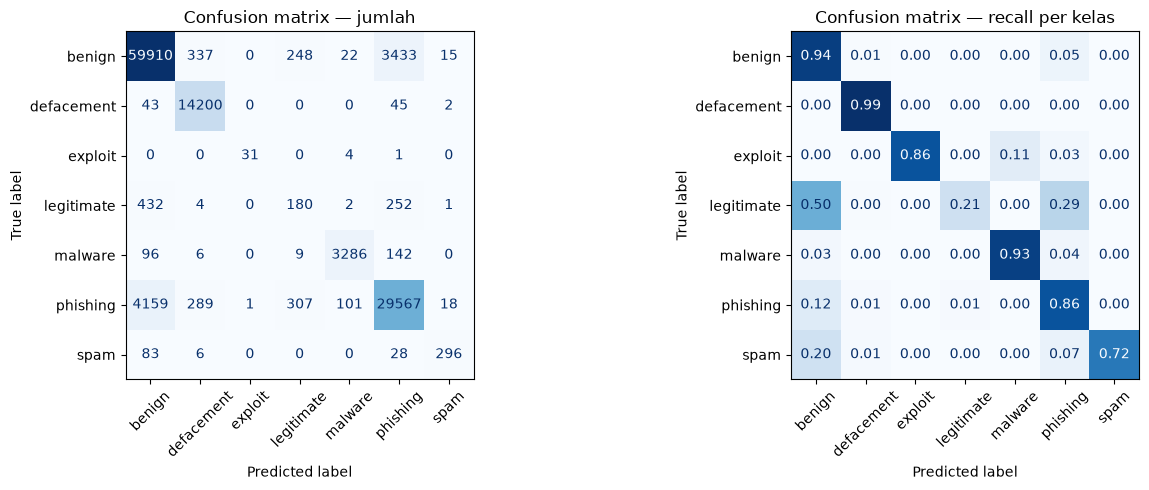

In [7]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

model_final = buat_knn(K_TERBAIK)
t0 = time.perf_counter()
model_final.fit(Xtr, y_train)
y_pred = model_final.predict(Xte)
print(f"Prediksi {Xte.shape[0]:,} baris test dalam {time.perf_counter() - t0:.1f} detik")

kelas = sorted(df.label.unique())
skor = {
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "macro_f1": f1_score(y_test, y_pred, labels=kelas, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_test, y_pred, labels=kelas, average="weighted", zero_division=0),
}
display(pd.Series(skor, name="test").to_frame().round(4))
print(classification_report(y_test, y_pred, labels=kelas, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=kelas)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(cm, display_labels=kelas).plot(
    ax=axes[0], cmap="Blues", colorbar=False, xticks_rotation=45, values_format="d")
axes[0].set_title("Confusion matrix — jumlah")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=kelas).plot(
    ax=axes[1], cmap="Blues", colorbar=False, xticks_rotation=45, values_format=".2f")
axes[1].set_title("Confusion matrix — recall per kelas")
plt.tight_layout()
plt.show()

## 7. Simpan hasil

Hasil diringkas ke JSON (konfigurasi + skor + hasil sweep) dan prediksi per baris
disimpan ke CSV terkompresi, supaya eksperimen bisa diaudit/dibandingkan nanti
tanpa menjalankan ulang.

In [8]:
ringkasan = {
    "notebook": "01_KNN_TFIDF_VP",
    "desain": "eksperimen pribadi dari nol (data penuh 783.702 baris, split acak stratified 70/15/15)",
    "seed": SEED,
    "jumlah_baris_bersih": int(len(df)),
    "split_rows": {"train": int(len(y_train)),
                   "validation": int(len(y_val)),
                   "test": int(len(y_test))},
    "tfidf": repr(tfidf),
    "kosakata": int(len(tfidf.vocabulary_)),
    "k_candidates": K_CANDIDATES,
    "k_terbaik": K_TERBAIK,
    "knn": repr(model_final),
    "sweep_validation": hasil_sweep,
    "test_metrics": {k: float(v) for k, v in skor.items()},
    "versi_paket": versi,
}
(RESULTS_DIR / "knn_tfidf_vp_metrics.json").write_text(
    json.dumps(ringkasan, indent=2, ensure_ascii=False), encoding="utf-8")

pd.DataFrame({"y_true": np.asarray(y_test), "y_pred": np.asarray(y_pred)}).to_csv(
    RESULTS_DIR / "knn_tfidf_vp_test_predictions.csv.gz",
    index=False, compression="gzip")
print("Hasil tersimpan di:", RESULTS_DIR.resolve())

Hasil tersimpan di: D:\Semester5\ML\244107020017_Machine_Learning\PBL\Exsperimen\results_vp


### Interpretasi hasil akhir

**Sel interpretasi:** merangkum hasil dalam format siap kutip untuk laporan — label
model + representasi, accuracy test, macro F1, kelas dengan F1 terendah, dan batas
keberlakuan desain. Sel ini **membaca file hasil yang sudah tersimpan** di
`results_vp/`, sehingga bisa dijalankan kapan saja tanpa mengulang training.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score

hasil = json.loads(Path("results_vp/knn_tfidf_vp_metrics.json").read_text(encoding="utf-8"))
pred = pd.read_csv("results_vp/knn_tfidf_vp_test_predictions.csv.gz")

label_model = f"KNN (k={hasil['k_terbaik']}, cosine)"
label_rep = f"TF-IDF karakter 3-5 gram (kosakata {hasil['kosakata']:,})"
kelas = sorted(pred.y_true.unique())
f1_kelas = pd.Series(
    f1_score(pred.y_true, pred.y_pred, labels=kelas, average=None, zero_division=0),
    index=kelas,
).sort_values()
terendah = f1_kelas.index[0]

print(f"{label_model} + {label_rep}:")
print(f"Accuracy test {hasil['test_metrics']['accuracy']:.2%}; macro F1 {hasil['test_metrics']['macro_f1']:.4f}.")
print(f"Kelas dengan F1 terendah: {terendah} ({f1_kelas.iloc[0]:.4f}).")
print("Model dilatih pada seluruh train; validation dan test hanya untuk evaluasi (k dipilih dari validation, bukan test).")
print("Hasil berlaku pada desain VP ini: split acak stratified 70/15/15 atas data penuh (bukan domain-disjoint);")
print("data tidak memuat timestamp, source, atau campaign.")
display(f1_kelas.to_frame("F1 per kelas").round(4))

KNN (k=5, cosine) + TF-IDF karakter 3-5 gram (kosakata 50,000):
Accuracy test 91.42%; macro F1 0.8073.
Kelas dengan F1 terendah: legitimate (0.2229).
Model dilatih pada seluruh train; validation dan test hanya untuk evaluasi (k dipilih dari validation, bukan test).
Hasil berlaku pada desain VP ini: split acak stratified 70/15/15 atas data penuh (bukan domain-disjoint);
data tidak memuat timestamp, source, atau campaign.


,F1 per kelas
legitimate,0.2229
spam,0.7946
phishing,0.8708
exploit,0.9118
benign,0.9311
malware,0.9451
defacement,0.9749


## 8. Kesimpulan dan limitasi versi VP

**Ringkasan alur:** data dibersihkan (kosong/konflik/duplikat dibuang) → seluruh
**783.702 baris** di-split acak stratified 70/15/15 → TF-IDF char_wb 3–5 gram (fit
hanya di train, L2) → KNN cosine distance-weighted, k dipilih di validation →
test dinilai sekali dengan fokus macro F1.

**Limitasi yang disadari (jangan diklaim lebih dari ini):**

1. **Split acak per-baris** — domain yang sama bisa menyeberang partisi, berbeda
   dari protokol kelompok yang domain-disjoint. Skor versi ini cenderung sedikit
   optimis dan **tidak apple-to-apple** dengan hasil notebook kelompok.
2. **Kelas `exploit` tetap sangat langka** (243 baris dari 783 ribu); skor kelas itu
   indikasi kasar, bukan kesimpulan.
3. **k dipilih dari sweep kecil** (4 kandidat) pada satu potongan validation.
4. Sekali pakai test tetap tidak membuktikan generalisasi ke data luar
   (URL baru/masa depan).

**Ide lanjutan:** turunkan `MAX_FEATURES` atau isi `K_CANDIDATES` bila ingin lebih
cepat; coba `analyzer="char"` atau `ngram_range` lain; bandingkan dengan jalur 54
fitur numerik; atau pakai protokol split domain-disjoint bila ingin membandingkan
langsung dengan kelompok.